# Introduction to Machine Learning – Lab 2
## Hyperparameter Tuning with SMOTE (notebook 05.1)

### Objective
In notebook 04, SMOTE was the only change that beat the baseline on average (+0.0115 macro-F1 over 70 splits). But the gain appeared only on the holdout splits, not on the stratified 5-fold cross-validation that notebook 05 used for tuning, so notebook 05 tuned the model without SMOTE. This notebook repeats notebook 05 with the same code, the same folds, the same search space and the same number of Optuna trials, with one difference: **every model is trained on SMOTE-balanced training data**. Two questions:
1. Do the hyperparameters behave differently when the small price classes are filled up with synthetic houses?
2. Does SMOTE together with tuned hyperparameters beat the tuned model of notebook 05?

**How SMOTE is applied:**
* As in notebook 04, SMOTE is a step of the pipeline (`build_pipeline(..., smote=True)`, see `smote_keep_missing` in `preprocessing.py`).
* It runs after the one-hot encoding and only on the training part of each split. Every price class is filled up with synthetic houses until it is as large as the largest one, and the test houses are always real houses.
* SMOTE must not be applied to the whole data set before splitting: synthetic houses interpolated from a test house would then land in the training part, and the test scores would be too optimistic.

The hyperparameters, the protocol of the manual experiments and the TPE sampler are explained in notebook 05. This notebook only interprets the new results.

In [1]:
import sys
import warnings
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler
from optuna.visualization import matplotlib as optuna_plots
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold

from evaluation import evaluate, make_splits, paired_differences, summarize
from preprocessing import CLASS_NAMES, build_pipeline, prepare_data

sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
# The matplotlib versions of the Optuna plots are marked as experimental
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

# Same data as notebooks 02–04
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
print(f"Dataset dimensions: X = {X.shape}, y = {y.shape}")

# All 70 splits of notebooks 02 and 04 (final comparison), and the 5 folds used for tuning
splits = make_splits(y)
cv5 = [split for split in splits if split["Setup"] == "CV k=5, stratified"]

# Default values of the studied hyperparameters in XGBoost: this is the baseline model of notebook 02
DEFAULTS = {
    "max_depth": 6,
    "learning_rate": 0.3,
    "n_estimators": 100,
    "min_child_weight": 1,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "reg_lambda": 1.0,
    "reg_alpha": 0.0,
    "gamma": 0.0,
}
METRICS = ["Train Macro-F1", "Test Macro-F1", "Test Macro-F1 Std", "Test Accuracy", "Gap"]


def make_model(smote=True, **params):
    """Pipeline of notebook 05 (one-hot + XGBoost), here with SMOTE on the training part by default."""
    return build_pipeline(
        "onehot", min_frequency=5, smote=smote, enable_categorical=False, tree_method="hist",
        **{**DEFAULTS, **params},
    )


def cv_scores(model):
    """Mean scores over the 5 stratified folds; Gap = training minus test macro-F1 (variance)."""
    scores = evaluate(model, X, y, cv5)
    return {
        "Train Macro-F1": scores["Train Macro-F1"].mean(),
        "Test Macro-F1": scores["Test Macro-F1"].mean(),
        # Sample standard deviation over the folds, as in notebook 04
        "Test Macro-F1 Std": scores["Test Macro-F1"].std(),
        "Test Accuracy": scores["Test Accuracy"].mean(),
        "Gap": scores["Train Macro-F1"].mean() - scores["Test Macro-F1"].mean(),
    }


baseline_scores = cv_scores(make_model())
print("Default hyperparameters + SMOTE, 5-fold stratified CV:")
display(pd.DataFrame([baseline_scores]).round(4))

Dataset dimensions: X = (2925, 72), y = (2925,)


Default hyperparameters + SMOTE, 5-fold stratified CV:


,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1.0,0.7479,0.0204,0.7638,0.2521


With SMOTE, the default model scores 0.7479 ± 0.0204 on the 5 stratified folds, the same value as the SMOTE variant in notebook 04 and slightly below the default model without SMOTE (0.7494). It still fits every training house perfectly (training macro-F1 1.0), with a gap of 0.2521. This row is the reference for every experiment below.

### 1. Manual hyperparameter tuning (with SMOTE)
The same experiments as in notebook 05, Section 1: one hyperparameter (or the pair `learning_rate` / `n_estimators`) is changed at a time, all others keep their default value, and every configuration is scored on the same 5 stratified folds (training macro-F1, test macro-F1 ± standard deviation, test accuracy, gap). The reference row in each experiment is now the default model **with** SMOTE.

In [2]:
def sweep(values, param=None):
    """Score one configuration per value; all hyperparameters that are not changed keep their default."""
    rows = []
    for value in values:
        # A dict changes several hyperparameters at once (e.g. learning_rate and n_estimators)
        params = value if isinstance(value, dict) else {param: value}
        rows.append({**params, **cv_scores(make_model(**params))})
    return pd.DataFrame(rows)

#### 1.1 Tree depth (`max_depth`)
Same values as in notebook 05, Section 1.1.

In [3]:
# Shallow trees (2–4) are strongly regularized; 8 and 10 allow more interactions than the default 6
sweep_depth = sweep([2, 3, 4, 6, 8, 10], "max_depth")
display(sweep_depth.round(4))

,max_depth,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,2,0.9093,0.7259,0.0208,0.7330,0.1833
1,3,0.9777,0.7397,0.0217,0.7491,0.2381
2,4,0.9978,0.7448,0.0302,0.7566,0.2530
3,6,1.0000,0.7479,0.0204,0.7638,0.2521
4,8,1.0000,0.7434,0.0177,0.7562,0.2566
5,10,1.0000,0.7367,0.0152,0.7491,0.2633


* As without SMOTE, shallower trees lower the training score (0.9093 at depth 2, 0.9777 at depth 3), and deeper trees than 6 are worse on the test folds (0.7434 at 8, 0.7367 at 10).
* Unlike in notebook 05, shallow trees now clearly hurt: 0.7259 at depth 2 (−0.022) and 0.7397 at depth 3, while without SMOTE depth 2 was as good as the default. With SMOTE, all six classes are equally large in the training data, so the trees have to separate all of them equally well, which a depth-2 tree cannot do (more bias). The default depth 6 is the best value.

#### 1.2 Learning rate and number of rounds (`learning_rate`, `n_estimators`)
Same values as in notebook 05, Section 1.2.

In [4]:
# learning_rate × n_estimators = 30 for the default, the two "slow" settings keep a similar product
sweep_rate = sweep([
    {"learning_rate": 0.3, "n_estimators": 100},   # default
    {"learning_rate": 0.3, "n_estimators": 300},   # more rounds at the default rate
    {"learning_rate": 0.1, "n_estimators": 100},   # smaller rate, same number of rounds
    {"learning_rate": 0.1, "n_estimators": 300},   # smaller rate, 3x the rounds
    {"learning_rate": 0.05, "n_estimators": 600},  # even smaller rate, 6x the rounds
])
display(sweep_rate.round(4))

,learning_rate,n_estimators,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.30,100,1.0000,0.7479,0.0204,0.7638,0.2521
1,0.30,300,1.0000,0.7431,0.0132,0.7556,0.2569
2,0.10,100,0.9939,0.7352,0.0205,0.7436,0.2587
3,0.10,300,1.0000,0.7508,0.0310,0.7579,0.2492
4,0.05,600,1.0000,0.7531,0.0224,0.7617,0.2469


* The pattern of notebook 05 repeats: more rounds at the default rate do not help (0.7431 with 300 rounds), and a smaller rate with too few rounds is clearly worse (0.7352 at 0.1 / 100).
* With proportionally more rounds, the smaller learning rates are now slightly better than the default: 0.7508 (0.1 / 300) and 0.7531 (0.05 / 600, +0.0052, with the smallest gap of this experiment, 0.2469). Small steps over many trees average out more of the noise that the synthetic houses add.

#### 1.3 Minimum leaf weight (`min_child_weight`)
Same values as in notebook 05, Section 1.3.

In [5]:
# Larger values forbid leaves that describe only a handful of houses
sweep_mcw = sweep([1, 3, 5, 10, 20], "min_child_weight")
display(sweep_mcw.round(4))

,min_child_weight,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1,1.0000,0.7479,0.0204,0.7638,0.2521
1,3,1.0000,0.7561,0.0219,0.7631,0.2439
2,5,1.0000,0.7508,0.0184,0.7597,0.2492
3,10,0.9982,0.7541,0.0242,0.7562,0.2441
4,20,0.9889,0.7464,0.0210,0.7501,0.2424


* Every value up to 10 is at least as good as the default: 0.7561 at 3 (+0.0082, the best), 0.7508 at 5, 0.7541 at 10. Only 20 is slightly worse (0.7464), with a lower training score (0.9889).
* Without SMOTE, larger values hurt, most likely because they removed the leaves for the few houses of the rare classes. With SMOTE, every class has as many training houses as the largest one, so a minimum leaf weight no longer excludes the rare classes. Instead, it prevents leaves that describe only a handful of (often synthetic) houses.

#### 1.4 Row and column subsampling (`subsample`, `colsample_bytree`)
Same values as in notebook 05, Section 1.4.

In [6]:
# Each tree is fitted on 100%, 80%, 60% or 40% of the training houses
sweep_subsample = sweep([1.0, 0.8, 0.6, 0.4], "subsample")
display(sweep_subsample.round(4))

# Each tree may use 100%, 80%, 50% or 30% of the 200 encoded features
sweep_colsample = sweep([1.0, 0.8, 0.5, 0.3], "colsample_bytree")
display(sweep_colsample.round(4))

,subsample,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1.0,1.0,0.7479,0.0204,0.7638,0.2521
1,0.8,1.0,0.7597,0.0254,0.7624,0.2403
2,0.6,1.0,0.7615,0.0155,0.7617,0.2385
3,0.4,1.0,0.7490,0.0359,0.7552,0.2510


,colsample_bytree,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1.0,1.0,0.7479,0.0204,0.7638,0.2521
1,0.8,1.0,0.7528,0.0321,0.7638,0.2472
2,0.5,1.0,0.7512,0.0223,0.7631,0.2488
3,0.3,1.0,0.7588,0.0272,0.7641,0.2412


* **Row subsampling now helps clearly:** 0.7597 at 0.8 (+0.0118) and 0.7615 at 0.6 (+0.0136, also with a small spread, ± 0.0155). Only 0.4 falls back to the default level (0.7490). Without SMOTE, subsampling had no effect.
* **Column subsampling helps as well:** 0.7528 at 0.8, 0.7512 at 0.5 and 0.7588 at 0.3 (+0.0109). Without SMOTE, 0.3 was the worst value (−0.012).
* **Explanation:** the training score stays 1.0 in every case, so the gain comes from better generalization alone. SMOTE adds many near-identical houses: the synthetic houses of a small class are all interpolations between the same few real houses (in notebook 04, about 16 synthetic houses per real house ≥ \$400k). A tree that sees all of them can carve a region around each such cluster. When every tree sees a random part of the houses, or only some of the features, such clusters and the patterns they contain differ from tree to tree, and the trees no longer fit them in the same way. This lowers the variance. A possible reason why few columns help so much here: a synthetic house is interpolated in all features at once, so combinations of features along these interpolation lines are an artifact of SMOTE, and a tree that only sees 30% of the features can rely less on such combinations.

#### 1.5 Penalties on the leaf values (`reg_lambda`, `reg_alpha`)
Same values as in notebook 05, Section 1.5.

In [7]:
# L2 penalty: default 1; 0 switches it off
sweep_lambda = sweep([0.0, 1.0, 5.0, 20.0, 50.0], "reg_lambda")
display(sweep_lambda.round(4))

# L1 penalty: default 0 (off)
sweep_alpha = sweep([0.0, 0.5, 2.0, 5.0], "reg_alpha")
display(sweep_alpha.round(4))

,reg_lambda,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.0,1.0000,0.7452,0.0246,0.7556,0.2548
1,1.0,1.0000,0.7479,0.0204,0.7638,0.2521
2,5.0,1.0000,0.7623,0.0222,0.7634,0.2377
3,20.0,0.9997,0.7562,0.0306,0.7641,0.2435
4,50.0,0.9959,0.7601,0.0230,0.7658,0.2358


,reg_alpha,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.0,1.0000,0.7479,0.0204,0.7638,0.2521
1,0.5,1.0000,0.7422,0.0233,0.7549,0.2578
2,2.0,0.9979,0.7458,0.0242,0.7545,0.2522
3,5.0,0.9797,0.7437,0.0115,0.7474,0.2361


* **L2 penalty:** $\lambda$ = 5 gives the best single result of all manual experiments: 0.7623 (+0.0144). Larger values stay above the default as well (0.7562 at 20, 0.7601 at 50), and switching the penalty off is worse (0.7452). Without SMOTE, no value above 1 helped.
* **L1 penalty:** still worse than the default (0.7422 at 0.5, 0.7458 at 2, 0.7437 at 5), but the losses are smaller than without SMOTE (−0.002 to −0.006 instead of −0.010 to −0.020).
* **Explanation:** $\lambda$ shrinks the leaf values $w^* = -G/(H + \lambda)$, and it shrinks them most for leaves with a small hessian sum $H$, i.e. leaves that contain few houses. With SMOTE, there are many such small groups of near-identical synthetic houses to isolate, so $\lambda$ removes more overfitting than it costs. $\alpha$ sets leaves with a summed gradient $|G| \le \alpha$ to 0. With SMOTE, the leaves of the rare classes contain many more houses and therefore larger $|G|$, so fewer of them are deleted than without SMOTE.

#### 1.6 Minimum split gain (`gamma`)
Same values as in notebook 05, Section 1.6.

In [8]:
# Splits with a gain below gamma are pruned
sweep_gamma = sweep([0.0, 0.5, 1.0, 2.0, 5.0], "gamma")
display(sweep_gamma.round(4))

,gamma,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.0,1.0000,0.7479,0.0204,0.7638,0.2521
1,0.5,0.9912,0.7389,0.0087,0.7497,0.2523
2,1.0,0.9777,0.7366,0.0094,0.7415,0.2411
3,2.0,0.9469,0.7362,0.0103,0.7378,0.2108
4,5.0,0.8783,0.7191,0.0125,0.7125,0.1592


* As without SMOTE, $\gamma$ is the strongest regularizer but makes the test score worse: the training macro-F1 falls to 0.8783 at $\gamma$ = 5 (gap 0.1592), and the test macro-F1 falls to 0.7389 (0.5), 0.7366 (1), 0.7362 (2) and 0.7191 (5).
* One difference: the spread over the folds becomes small (± 0.0087–0.0125 instead of ± 0.0204). Pruning the weak splits makes the model more stable, but it removes real patterns along with the noise (more bias).

#### 1.7 Overview of all manual experiments
Training and test macro-F1 for every value of every experiment (error bars: ± one standard deviation over the 5 folds).

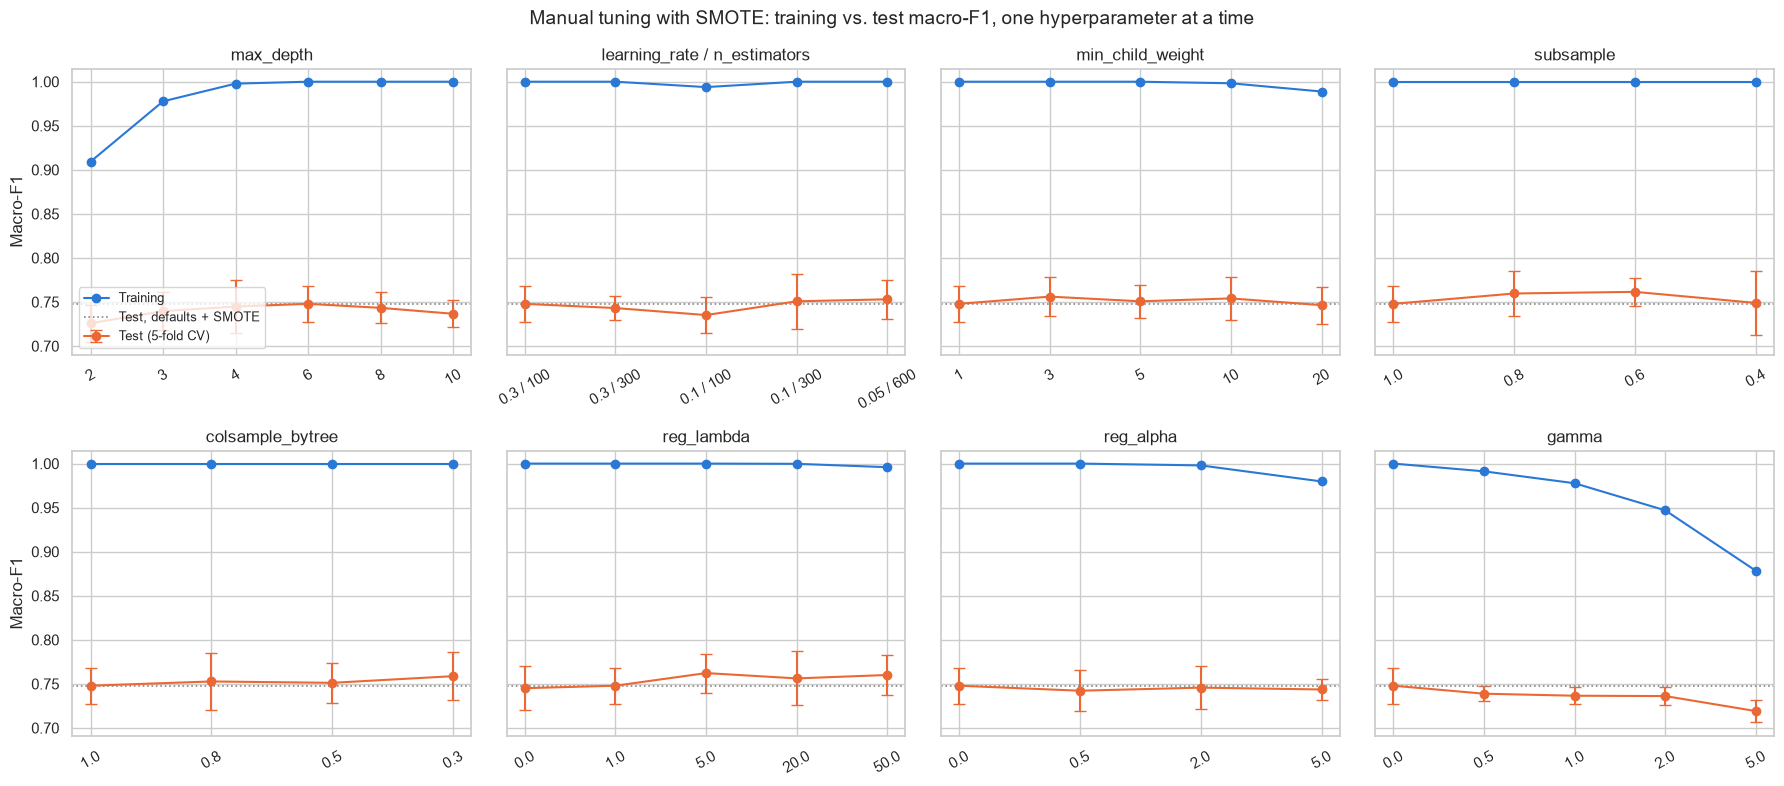

In [9]:
SWEEPS = {
    "max_depth": sweep_depth,
    "learning_rate / n_estimators": sweep_rate,
    "min_child_weight": sweep_mcw,
    "subsample": sweep_subsample,
    "colsample_bytree": sweep_colsample,
    "reg_lambda": sweep_lambda,
    "reg_alpha": sweep_alpha,
    "gamma": sweep_gamma,
}


def value_labels(df):
    """Axis labels of a sweep, e.g. "0.1 / 300" for learning_rate / n_estimators."""
    params = [col for col in df.columns if col not in METRICS]
    return df[params].astype(str).agg(" / ".join, axis=1)


fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, (name, df) in zip(axes.flat, SWEEPS.items()):
    labels = value_labels(df)
    ax.plot(labels, df["Train Macro-F1"], marker="o", color="#2a78d6", label="Training")
    ax.errorbar(labels, df["Test Macro-F1"], yerr=df["Test Macro-F1 Std"], marker="o", capsize=4,
                color="#eb6834", label="Test (5-fold CV)")
    ax.axhline(baseline_scores["Test Macro-F1"], color="#898781", linestyle=":", linewidth=1.2,
               label="Test, defaults + SMOTE")
    ax.set_title(name, fontsize=12)
    ax.tick_params(axis="x", rotation=30)
for ax in axes[:, 0]:
    ax.set_ylabel("Macro-F1")
axes[0, 0].legend(loc="lower left", fontsize=9)
fig.suptitle("Manual tuning with SMOTE: training vs. test macro-F1, one hyperparameter at a time", fontsize=14)
plt.tight_layout()
plt.show()

#### Interpretation of the manual experiments with SMOTE
* **Several single changes now help:** five of them raise the test macro-F1 by more than 0.01: $\lambda$ = 5 (+0.0144), `subsample` = 0.6 (+0.0136), $\lambda$ = 50 (+0.0122), `subsample` = 0.8 (+0.0118) and `colsample_bytree` = 0.3 (+0.0109). Without SMOTE (notebook 05), no single change helped by more than 0.003.
* **They lower the gap by raising the test score:** the training macro-F1 stays at 0.995 or above for all five. The changes that lower the training score (shallow trees, $\gamma$, large $\alpha$) make the test score worse, as without SMOTE.
* **Bias-variance:** SMOTE adds variance. Half of the training houses are synthetic, and the model can memorize the artificial patterns between them. Regularization that targets exactly this kind of overfitting (row and column sampling, L2 shrinkage of small leaves) removes it without adding much bias. With SMOTE, the default model is no longer at the best point along these axes.

#### 1.8 Combining the best values
As in notebook 05: the best value of every experiment, combined.

In [10]:
# Best test macro-F1 of every experiment; if the default value wins, the default stays
manual_params = {}
for df in SWEEPS.values():
    best = df.loc[df["Test Macro-F1"].idxmax()]
    manual_params.update({col: best[col] for col in df.columns if col not in METRICS})
# Integer hyperparameters come back as floats from the data frame
manual_params = {k: int(v) if k in ("max_depth", "n_estimators") else float(v) for k, v in manual_params.items()}
changed = {k: v for k, v in manual_params.items() if v != DEFAULTS[k]}
print("Changed against the defaults:", changed)

manual_scores = cv_scores(make_model(**manual_params))
display(pd.DataFrame(
    [baseline_scores, manual_scores], index=["Defaults + SMOTE", "Manual combination + SMOTE"]
).round(4))

Changed against the defaults: {'learning_rate': 0.05, 'n_estimators': 600, 'min_child_weight': 3.0, 'subsample': 0.6, 'colsample_bytree': 0.3, 'reg_lambda': 5.0}


,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
Defaults + SMOTE,1.0000,0.7479,0.0204,0.7638,0.2521
Manual combination + SMOTE,0.9973,0.7606,0.0267,0.7634,0.2367


* The combination changes six values: `learning_rate` 0.05 with 600 rounds, `min_child_weight` 3, `subsample` 0.6, `colsample_bytree` 0.3 and `reg_lambda` 5. It reaches 0.7606 ± 0.0267, +0.0127 over the default with SMOTE, with a training macro-F1 of 0.9973 and a gap of 0.2367.
* On these 5 folds it is not better than the best single changes ($\lambda$ = 5: 0.7623, `subsample` 0.6: 0.7615). As in notebook 05, gains chosen on the same folds do not simply add up. Section 4 shows that this combination generalizes better to the other splits than any single model in this notebook.

### 2. Bayesian optimization with Optuna (`TPESampler`)
Same objective (mean macro-F1 over the same 5 stratified folds), search space, sampler (`TPESampler`, 10 random startup trials, seed 42), pruner and number of trials (100) as in notebook 05, Section 2. SMOTE runs inside every fold. The trials are stored in the same SQLite database `optuna_ames_housing.db` under a new study name, `xgboost_smote_macro_f1_tpe`, so the search of notebook 05 is not touched and an interrupted run resumes where it stopped.

In [11]:
STORAGE = "sqlite:///optuna_ames_housing.db"
STUDY_NAME = "xgboost_smote_macro_f1_tpe"
N_TRIALS = 100


def objective(trial):
    """Mean macro-F1 over the 5 stratified folds for one hyperparameter combination."""
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 30.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.4, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.001, 10.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
    }
    model = make_model(**params)

    fold_scores = []
    for step, split in enumerate(cv5):
        fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
        fold_scores.append(f1_score(y.loc[split["test"]], fitted.predict(X.loc[split["test"]]), average="macro"))
        # Running mean after each fold, so the pruner can stop clearly bad trials early
        trial.report(np.mean(fold_scores), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(fold_scores)


def print_progress(study, trial):
    """Short status line after every 10 trials."""
    if (trial.number + 1) % 10 == 0:
        print(f"{trial.number + 1:>3} trials: best macro-F1 {study.best_value:.4f} (trial {study.best_trial.number})")


study = optuna.create_study(
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
    direction="maximize",
    sampler=TPESampler(n_startup_trials=10, seed=42),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1),
)

# Resume: only the trials that are not yet stored in the database are run
remaining = N_TRIALS - len(study.trials)
print(f"{len(study.trials)} trials already stored, running {max(remaining, 0)} more.")
if remaining > 0:
    study.optimize(objective, n_trials=remaining, callbacks=[print_progress])

trials = study.trials_dataframe()
print("\nTrial states:", trials["state"].value_counts().to_dict())
print(f"Best trial: #{study.best_trial.number} with mean macro-F1 {study.best_value:.4f}")

# The 10 best finished trials, with their hyperparameters
top = trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False).head(10)
top = top[["number", "value"] + [col for col in trials if col.startswith("params_")]]
display(top.rename(columns=lambda col: col.removeprefix("params_")).set_index("number").round(4))

0 trials already stored, running 100 more.


 10 trials: best macro-F1 0.7555 (trial 2)


 20 trials: best macro-F1 0.7617 (trial 16)


 30 trials: best macro-F1 0.7654 (trial 23)


 40 trials: best macro-F1 0.7654 (trial 23)


...

 70 trials: best macro-F1 0.7654 (trial 23)


 80 trials: best macro-F1 0.7654 (trial 23)


 90 trials: best macro-F1 0.7654 (trial 23)


100 trials: best macro-F1 0.7654 (trial 23)

Trial states: {'COMPLETE': 98, 'PRUNED': 2}
Best trial: #23 with mean macro-F1 0.7654


,value,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
number,,,,,,,,,,
23,0.7654,0.5215,0.9807,0.1367,6,1.7384,900,0.0948,3.0722,0.5100
21,0.7633,0.6081,1.5071,0.0925,6,3.2553,800,0.2917,3.0217,0.4958
51,0.7633,0.5034,1.3705,0.1278,7,1.8029,850,0.3800,4.9151,0.5233
72,0.7632,0.4626,1.4631,0.1271,7,2.2345,950,0.0638,19.3732,0.5535
68,0.7618,0.5369,1.0191,0.1143,7,1.4296,800,0.2158,8.1507,0.5491
16,0.7617,0.4899,0.8636,0.0387,6,3.1257,800,0.3136,5.5778,0.4644
85,0.7613,0.5619,1.2366,0.1242,6,1.3574,900,0.0296,5.5172,0.5352
77,0.7611,0.5159,1.3222,0.1462,6,1.4063,800,0.0646,6.4524,0.5129
91,0.7609,0.4972,0.9207,0.1227,5,1.4172,800,0.0707,4.1193,0.5048


#### Interpretation of the search result
* **Best trial:** #23 with 0.7654 on the 5 folds. That is +0.0175 over the default with SMOTE (0.7479), +0.0048 over the manual combination (0.7606), and +0.0098 over the best trial of notebook 05 on the same folds (0.7556). 98 trials finished and 2 were pruned.
* **Best hyperparameters:** `max_depth` 6, `learning_rate` 0.1367 with 900 rounds, `subsample` 0.510, `colsample_bytree` 0.522, `min_child_weight` 1.74, `gamma` 0.981, `reg_lambda` 3.07, `reg_alpha` 0.0948.
* **The 10 best trials agree:**
  * depth 5–7
  * learning rate 0.039–0.146 with 800–950 rounds
  * `subsample` 0.46–0.55 and `colsample_bytree` 0.46–0.61
  * `min_child_weight` 1.36–3.26
  * `gamma` 0.86–1.51, `reg_lambda` 3.0–19.4 and `reg_alpha` 0.03–0.38

  Their scores lie within 0.0047 of each other (0.7607–0.7654).
* **The optimum moves compared with notebook 05**, whose 10 best trials had:
  * depth 4–5 instead of 5–7
  * learning rate 0.027–0.056 instead of 0.039–0.146
  * `reg_lambda` 0.03–0.57 instead of 3.0–19.4
  * `gamma` 0.05–0.69 instead of 0.86–1.51
  * practically no L1 penalty (`reg_alpha` ≤ 0.012) instead of 0.03–0.38
  * `subsample` 0.58–0.76 instead of 0.46–0.55

  With SMOTE, the training part is about twice as large (4,974 instead of 2,340 houses in notebook 04's first fold), which supports deeper trees and larger steps. At the same time, stronger penalties and stronger row sampling keep the trees from fitting the details of the synthetic houses, which matches the manual experiments.

### 3. Visualizations of the optimization process
The same plots as in notebook 05, Section 3. First, how the search progressed: the optimization history and the running mean macro-F1 after each fold (pruned trials end early).

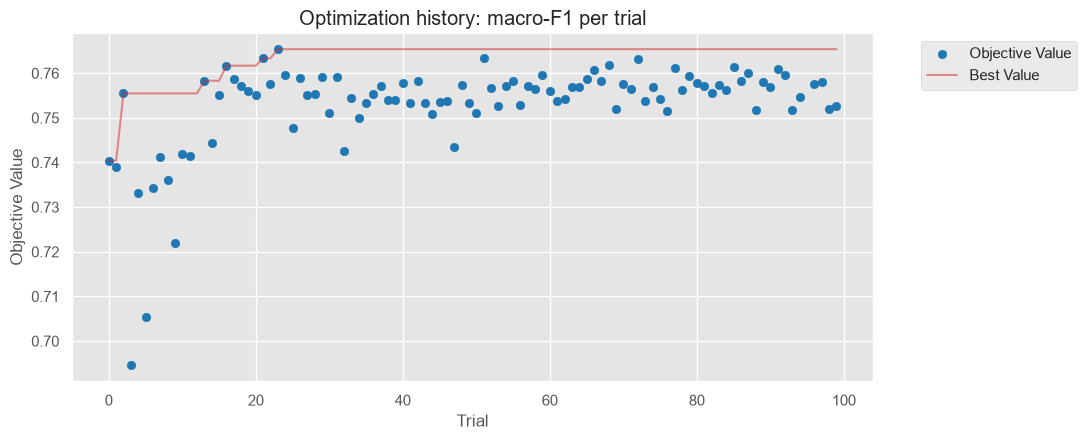

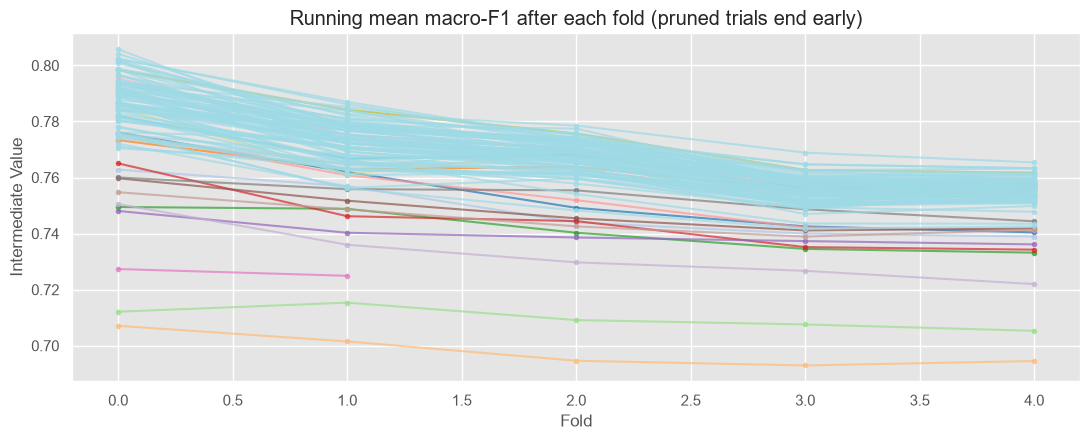

In [12]:
ax = optuna_plots.plot_optimization_history(study)
ax.figure.set_size_inches(11, 4.5)
ax.set_title("Optimization history: macro-F1 per trial")
plt.show()

ax = optuna_plots.plot_intermediate_values(study)
ax.figure.set_size_inches(11, 4.5)
ax.set_title("Running mean macro-F1 after each fold (pruned trials end early)")
ax.set_xlabel("Fold")
if ax.get_legend() is not None:
    ax.get_legend().remove()  # one entry per trial, too many to read
plt.show()

#### Interpretation of the search progress
* **Random start:** the 10 startup trials range from below 0.70 to 0.7555 (trial 2).
* **TPE phase:** the best value improves in steps up to 0.7654 (trial 23), and then not at all in the last 77 trials. Most later trials lie in a band between about 0.75 and 0.765, so the search has converged early. Further trials would at most bring gains far below the noise between folds.
* **Pruning:** only 2 of the 100 trials were stopped, compared with 11 in notebook 05. With SMOTE, the trials are presumably closer to each other in quality, so few fall clearly below the median after the second fold.

Next, which hyperparameters mattered: fANOVA importance, slice plots, parallel coordinates (five most important hyperparameters) and the contour plot of the two most important ones.

Hyperparameter importance (fANOVA):
reg_alpha           0.479
gamma               0.259
n_estimators        0.156
colsample_bytree    0.057
subsample           0.020
min_child_weight    0.010
learning_rate       0.009
reg_lambda          0.008
max_depth           0.002


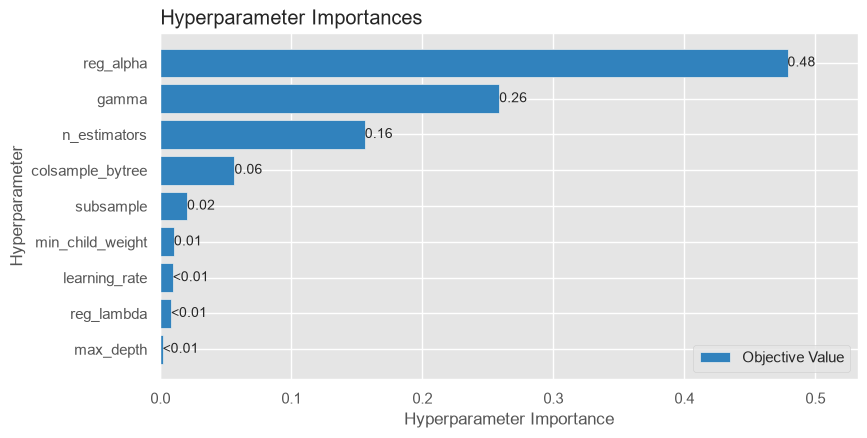

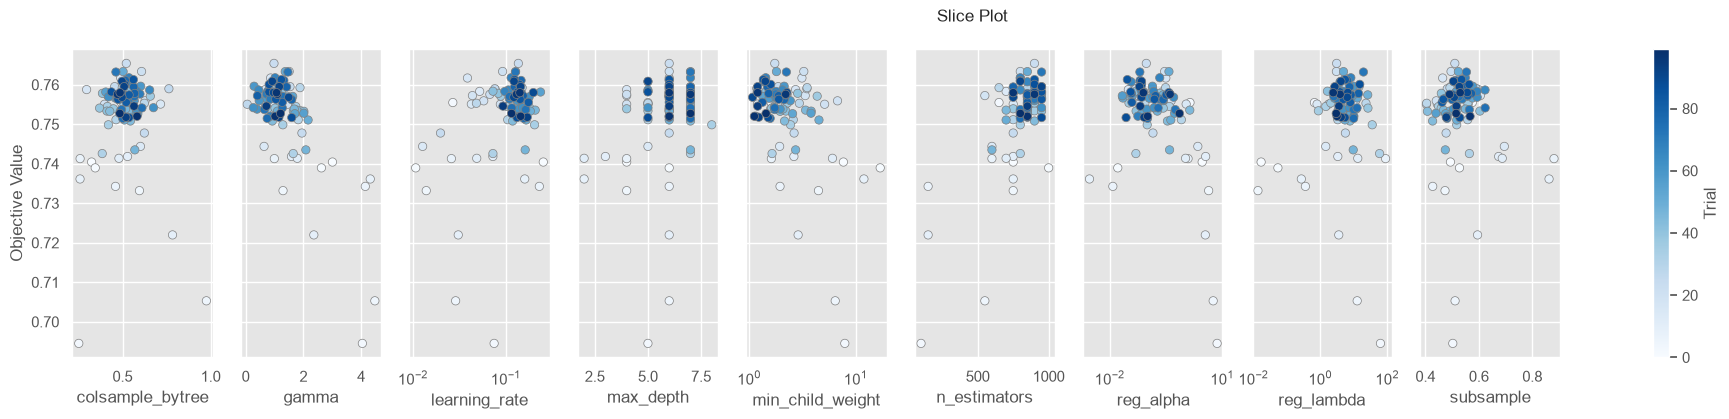

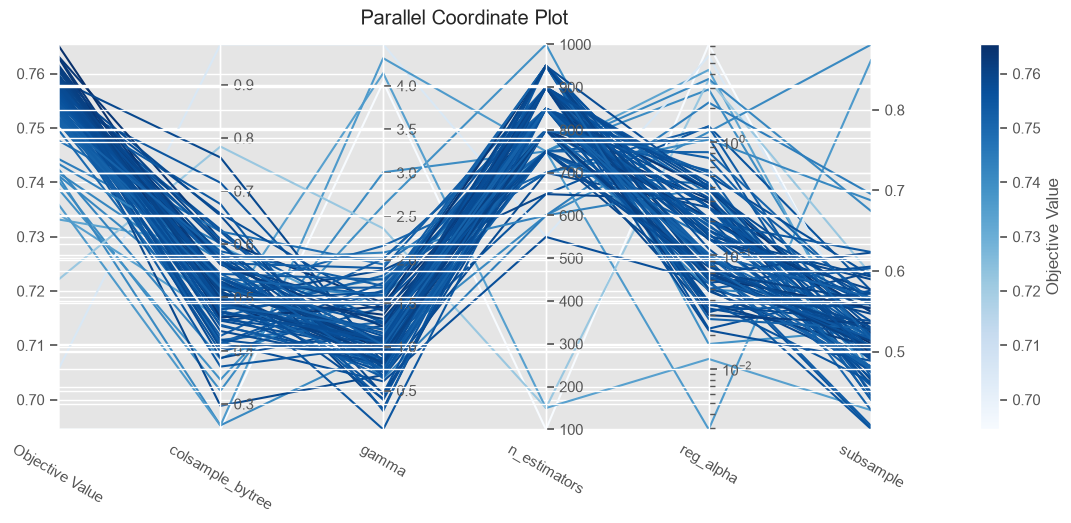

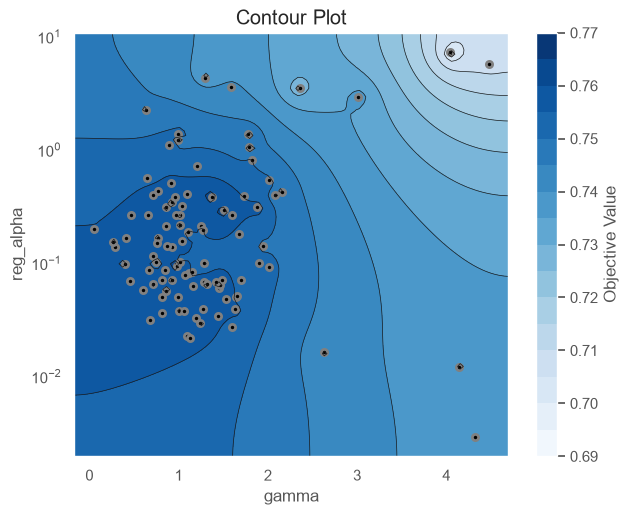

In [13]:
# Fixed seed so that the fANOVA importances are reproducible
evaluator = optuna.importance.FanovaImportanceEvaluator(seed=42)
importances = optuna.importance.get_param_importances(study, evaluator=evaluator)
print("Hyperparameter importance (fANOVA):")
print(pd.Series(importances).round(3).to_string())

ax = optuna_plots.plot_param_importances(study, evaluator=evaluator)
ax.figure.set_size_inches(9, 4.5)
plt.show()

axes = optuna_plots.plot_slice(study)
axes.flat[0].figure.set_size_inches(24, 4)
plt.show()

# Only the five most important hyperparameters, otherwise the axis labels overlap
ax = optuna_plots.plot_parallel_coordinate(study, params=list(importances)[:5])
ax.figure.set_size_inches(14, 5)
plt.show()

top_two = list(importances)[:2]
ax = optuna_plots.plot_contour(study, params=top_two)
ax.figure.set_size_inches(7, 5.5)
plt.show()

#### Interpretation of the hyperparameter importance
* **Importance:** `reg_alpha` (0.479), `gamma` (0.259) and `n_estimators` (0.156) explain most of the variation in macro-F1. All others have 0.057 or less, among them `reg_lambda` (0.008) and `max_depth` (0.002).
* **Where it comes from:** as in notebook 05, the importance is driven by the bad trials. The contour plot shows the worst region at large $\gamma$ and large $\alpha$ together, and the slice plots show low scores for few rounds. Once these are avoided, the remaining hyperparameters change the score only a little.
* **`reg_lambda` with importance 0.008**, although $\lambda$ = 5 was the best single manual change: TPE moved $\lambda$ into the range 3–19 early on, and inside this range the score hardly depends on it. Importance estimates from a guided search only describe the region that was actually explored.

### 4. Final model
As in notebook 05, the tuned models are evaluated again on all 70 splits (holdout 10% / 20% and CV $k$ = 5 / 10, each with and without stratification), since `study.best_value` is optimistic. Besides the three SMOTE models (defaults, manual combination, best Optuna trial), two models without SMOTE are included as references:
* the baseline with default hyperparameters
* the best Optuna trial of notebook 05, loaded from its study in the database

The paired differences are shown twice: against the baseline, as in notebook 05, and against the tuned model of notebook 05, which answers the main question of this notebook.

In [14]:
best_params = study.best_params
# Best trial of notebook 05 (tuned without SMOTE), loaded from its study in the same database
best_params_05 = optuna.load_study(study_name="xgboost_macro_f1_tpe", storage=STORAGE).best_params
REFERENCE = "Notebook 05 best (no SMOTE)"
MODELS = {
    "Baseline (no SMOTE)": make_model(smote=False),
    REFERENCE: make_model(smote=False, **best_params_05),
    "SMOTE + defaults": make_model(),
    "SMOTE + manual combination": make_model(**manual_params),
    "SMOTE + Optuna best": make_model(**best_params),
}

final_results = pd.concat(
    [evaluate(model, X, y, splits).assign(Variant=name) for name, model in MODELS.items()], ignore_index=True
)

print("Test macro-F1, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Macro-F1"))
print("Test accuracy, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Accuracy"))

# Bias-variance: training vs. test macro-F1, averaged over all 70 splits
gap = final_results.groupby("Variant", sort=False)[["Train Macro-F1", "Test Macro-F1"]].mean()
gap["Gap"] = gap["Train Macro-F1"] - gap["Test Macro-F1"]
print("Training vs. test macro-F1 over all 70 splits")
display(gap.round(4))

# Paired differences on the same split (positive = better than the reference): to the baseline as in
# notebook 05, and to the tuned model of notebook 05, which answers whether SMOTE adds anything
for reference in ["Baseline (no SMOTE)", REFERENCE]:
    differences = paired_differences(final_results, reference)
    experiment = differences.index.get_level_values("Setup").str.split().str[0]
    print(f"Macro-F1 minus the macro-F1 of \"{reference}\" on the same split")
    display(pd.concat({
        name: pd.DataFrame({
            "Mean Difference": group.mean(),
            "Std": group.std(),
            "Better": (group > 0).sum(),
            "Worse": (group < 0).sum(),
        })
        for name, group in [*differences.groupby(experiment, sort=False), ("All 70 splits", differences)]
    }, axis=1).round(4))

Test macro-F1, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline (no SMOTE),0.7486 ± 0.0238,0.7596 ± 0.0342,0.7357 ± 0.0172,0.7546 ± 0.0245,0.7421 ± 0.0286,0.7494 ± 0.0236,0.7574 ± 0.0252,0.7546 ± 0.0432
Notebook 05 best (no SMOTE),0.7595 ± 0.0290,0.7699 ± 0.0381,0.7563 ± 0.0145,0.7656 ± 0.0198,0.7549 ± 0.0190,0.7556 ± 0.0187,0.7516 ± 0.0212,0.7502 ± 0.0481
SMOTE + defaults,0.7688 ± 0.0224,0.7800 ± 0.0239,0.7579 ± 0.0217,0.7671 ± 0.0189,0.7445 ± 0.0235,0.7479 ± 0.0204,0.7535 ± 0.0351,0.7634 ± 0.0342
SMOTE + manual combination,0.7796 ± 0.0240,0.7830 ± 0.0223,0.7672 ± 0.0169,0.7779 ± 0.0185,0.7632 ± 0.0234,0.7606 ± 0.0267,0.7671 ± 0.0269,0.7703 ± 0.0387
SMOTE + Optuna best,0.7697 ± 0.0231,0.7777 ± 0.0150,0.7538 ± 0.0116,0.7719 ± 0.0201,0.7492 ± 0.0271,0.7654 ± 0.0221,0.7598 ± 0.0220,0.7670 ± 0.0315


Test accuracy, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline (no SMOTE),0.7546 ± 0.0198,0.7689 ± 0.0311,0.7547 ± 0.0121,0.7615 ± 0.0176,0.7542 ± 0.0235,0.7641 ± 0.0215,0.7648 ± 0.0212,0.7665 ± 0.0329
Notebook 05 best (no SMOTE),0.7683 ± 0.0226,0.7799 ± 0.0260,0.7704 ± 0.0118,0.7759 ± 0.0077,0.7648 ± 0.0150,0.7768 ± 0.0202,0.7685 ± 0.0199,0.7716 ± 0.0312
SMOTE + defaults,0.7659 ± 0.0191,0.7734 ± 0.0215,0.7610 ± 0.0164,0.7660 ± 0.0152,0.7470 ± 0.0165,0.7638 ± 0.0121,0.7614 ± 0.0187,0.7644 ± 0.0266
SMOTE + manual combination,0.7700 ± 0.0218,0.7788 ± 0.0209,0.7651 ± 0.0102,0.7742 ± 0.0129,0.7634 ± 0.0166,0.7634 ± 0.0238,0.7689 ± 0.0226,0.7716 ± 0.0310
SMOTE + Optuna best,0.7672 ± 0.0196,0.7727 ± 0.0169,0.7537 ± 0.0124,0.7706 ± 0.0123,0.7508 ± 0.0158,0.7644 ± 0.0265,0.7600 ± 0.0157,0.7692 ± 0.0310


Training vs. test macro-F1 over all 70 splits


,Train Macro-F1,Test Macro-F1,Gap
Variant,,,
Baseline (no SMOTE),1.0000,0.7509,0.2491
Notebook 05 best (no SMOTE),0.9883,0.7583,0.2300
SMOTE + defaults,1.0000,0.7624,0.2376
SMOTE + manual combination,0.9968,0.7724,0.2244
SMOTE + Optuna best,0.9713,0.7653,0.2060


Macro-F1 minus the macro-F1 of "Baseline (no SMOTE)" on the same split


Holdout                       \
                            Mean Difference     Std Better Worse   
Variant                                                            
Notebook 05 best (no SMOTE)          0.0132  0.0199     31     9   
SMOTE + defaults                     0.0188  0.0262     30    10   
SMOTE + manual combination           0.0273  0.0206     35     5   
SMOTE + Optuna best                  0.0187  0.0217     31     9   

                                         CV                       \
                            Mean Difference     Std Better Worse   
Variant                                                            
Notebook 05 best (no SMOTE)         -0.0002  0.0247     16    14   
SMOTE + defaults                     0.0018  0.0235     14    16   
SMOTE + manual combination           0.0139  0.0227     22     8   
SMOTE + Optuna best                  0.0088  0.0222     20    10   

                              All 70 splits                       
                            Mean Difference     Std Better Worse  
Variant                                                           
Notebook 05 best (no SMOTE)          0.0074  0.0229     47    23  
SMOTE + defaults                     0.0115  0.0263     44    26  
SMOTE + manual combination           0.0215  0.0224     57    13  
SMOTE + Optuna best                  0.0144  0.0223     51    19

Macro-F1 minus the macro-F1 of "Notebook 05 best (no SMOTE)" on the same split


Holdout                       \
                           Mean Difference     Std Better Worse   
Variant                                                           
Baseline (no SMOTE)                -0.0132  0.0199      9    31   
SMOTE + defaults                    0.0056  0.0262     23    17   
SMOTE + manual combination          0.0141  0.0214     29    11   
SMOTE + Optuna best                 0.0055  0.0219     22    18   

                                        CV                       \
                           Mean Difference     Std Better Worse   
Variant                                                           
Baseline (no SMOTE)                 0.0002  0.0247     14    16   
SMOTE + defaults                    0.0020  0.0252     12    18   
SMOTE + manual combination          0.0141  0.0206     20    10   
SMOTE + Optuna best                 0.0090  0.0283     16    14   

                             All 70 splits                       
                           Mean Difference     Std Better Worse  
Variant                                                          
Baseline (no SMOTE)                -0.0074  0.0229     23    47  
SMOTE + defaults                    0.0041  0.0256     35    35  
SMOTE + manual combination          0.0141  0.0209     49    21  
SMOTE + Optuna best                 0.0070  0.0247     38    32

#### Interpretation of the final comparison
* **SMOTE + manual combination is the best model:**
  * mean test macro-F1 of 0.7724 over all 70 splits
  * the best mean in 7 of the 8 setups, all except "CV k=5, stratified", the folds that the Optuna search was tuned on
  * better than the baseline by 0.0215 (on 57 of 70 splits)
  * **better than the tuned model of notebook 05 by 0.0141, on 49 of 70 splits**, with the same gain on the holdout splits (+0.0141, 29 of 40) and on the cross-validation folds (+0.0141, 20 of 30). Of all comparisons in notebooks 04–05.1, this is the most consistent gain.
* **SMOTE + Optuna best generalizes less well:** it is the best model on its own tuning folds (0.7654), but its mean over all 70 splits is only 0.7653. Against the tuned model of notebook 05, it gains just 0.0070 and is better on only 38 of 70 splits. This is the selection bias of the best of 100 trials on the same 5 folds. It is also the most regularized model (training macro-F1 0.9713, the smallest gap at 0.2060), but a smaller gap here comes with more bias, not a higher test score.
* **SMOTE with default hyperparameters** gains only 0.0041 over the tuned model of notebook 05 (better on 35 of 70). SMOTE pays off together with the matching regularization, not alone.
* **Accuracy does not rise:** the manual SMOTE combination has a lower accuracy than the tuned model of notebook 05 in 5 of the 8 setups, the same in one, and a higher one in two. SMOTE shifts predictions towards the small classes, which raises macro-F1, where every class counts equally, while the many houses of the large classes lose a little (Section 4.1).
* **How certain is it:** +0.0141 against notebook 05 is still smaller than the standard deviation of the paired differences (0.0209), and the 70 splits are not independent. In addition, the final model is the best of five candidates compared on these same splits, so its 0.7724 is slightly optimistic. But unlike in the earlier notebooks, the gain is consistent in both holdout and cross-validation.

#### 4.1 Diagnostics per class
Pooled out-of-fold predictions of the 5 stratified folds for three models:
* the tuned model of notebook 05 (no SMOTE)
* SMOTE + manual combination, the best model over all 70 splits in Section 4 (`FINAL`)
* SMOTE + best Optuna trial

The section shows metrics per class and the confusion matrices. Finally, the nested threshold check of notebook 03, Section 5, for the final model.

Pooled out-of-fold metrics


,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Notebook 05 best (no SMOTE),0.7768,0.7885,0.7368,0.7592
SMOTE + manual combination,0.7634,0.7667,0.7589,0.7626
SMOTE + Optuna best,0.7644,0.7650,0.7672,0.7660


Precision, recall and F1 per class


Notebook 05 best (no SMOTE)                  \
                            Precision  Recall      F1   
< 100k                         0.7822  0.6667  0.7198   
100k–130k                      0.6936  0.6582  0.6754   
130k–180k                      0.7794  0.8456  0.8111   
180k–250k                      0.7935  0.7865  0.7900   
250k–400k                      0.8312  0.8186  0.8249   
≥ 400k                         0.8511  0.6452  0.7339   

          SMOTE + manual combination                 SMOTE + Optuna best  \
                           Precision  Recall      F1           Precision   
< 100k                        0.7342  0.6878  0.7102              0.7284   
100k–130k                     0.6458  0.6699  0.6577              0.6578   
130k–180k                     0.7898  0.7905  0.7902              0.7961   
180k–250k                     0.7805  0.7851  0.7828              0.7713   
250k–400k                     0.8303  0.8136  0.8219              0.8266   
≥ 400k                        0.8197  0.8065  0.8130              0.8095   

                           
           Recall      F1  
< 100k     0.7131  0.7207  
100k–130k  0.6798  0.6686  
130k–180k  0.7799  0.7879  
180k–250k  0.7792  0.7753  
250k–400k  0.8287  0.8277  
≥ 400k     0.8226  0.8160

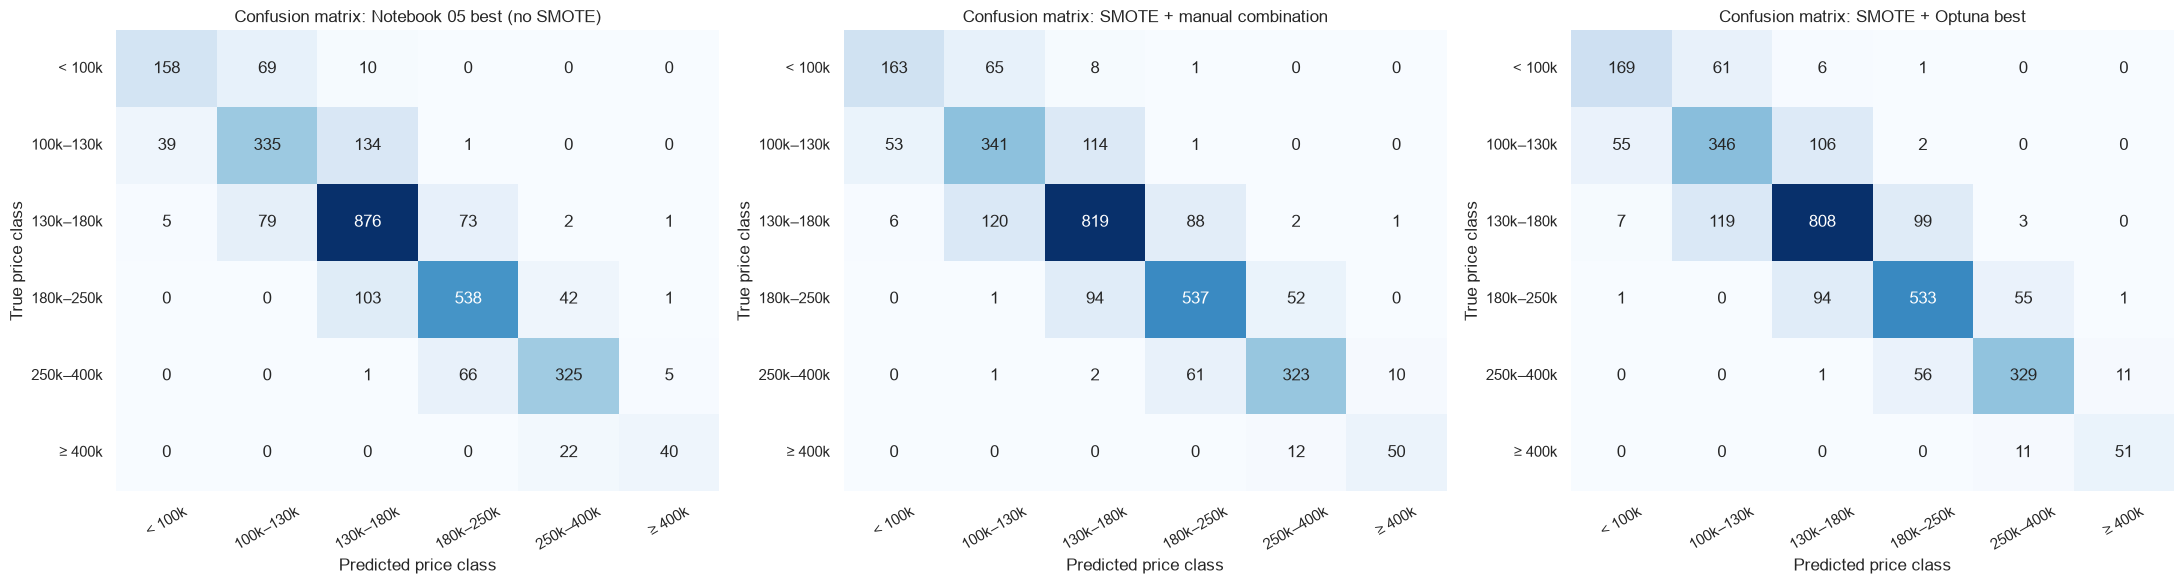

SMOTE + manual combination: 692 misclassified houses, 669 of them (96.7%) in an adjacent class



SMOTE + manual combination: default argmax vs. joint search thresholds (nested)


,Accuracy,Macro F1
Decision rule,,
Default argmax,0.7634,0.7626
Joint search thresholds (nested),0.7579,0.7523


In [15]:
def out_of_fold_proba(model):
    """Out-of-fold class probabilities on the 5 stratified folds."""
    proba = np.zeros((len(y), len(CLASS_NAMES)))
    for split in cv5:
        fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
        proba[y.index.get_indexer(split["test"])] = fitted.predict_proba(X.loc[split["test"]])
    return proba


y_arr = y.to_numpy()
# The best model over all 70 splits (Section 4) and the best Optuna trial, next to the tuned model of notebook 05
FINAL = "SMOTE + manual combination"
DIAGNOSED = [REFERENCE, FINAL, "SMOTE + Optuna best"]
oof = {name: out_of_fold_proba(MODELS[name]) for name in DIAGNOSED}
oof_pred = {name: proba.argmax(axis=1) for name, proba in oof.items()}

print("Pooled out-of-fold metrics")
display(pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_arr, pred),
        "Macro Precision": precision_score(y_arr, pred, average="macro"),
        "Macro Recall": recall_score(y_arr, pred, average="macro"),
        "Macro F1": f1_score(y_arr, pred, average="macro"),
    }
    for name, pred in oof_pred.items()
]).set_index("Model").round(4))

print("Precision, recall and F1 per class")
display(pd.concat({
    name: pd.DataFrame({
        "Precision": precision_score(y_arr, pred, average=None),
        "Recall": recall_score(y_arr, pred, average=None),
        "F1": f1_score(y_arr, pred, average=None),
    }, index=CLASS_NAMES)
    for name, pred in oof_pred.items()
}, axis=1).round(4))

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for ax, (name, pred) in zip(axes, oof_pred.items()):
    sns.heatmap(confusion_matrix(y_arr, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"Confusion matrix: {name}", fontsize=12)
    ax.set_xlabel("Predicted price class")
    ax.set_ylabel("True price class")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

tuned_pred = oof_pred[FINAL]
off_by_one = (np.abs(y_arr - tuned_pred) == 1).sum()
errors = (y_arr != tuned_pred).sum()
print(f"{FINAL}: {errors} misclassified houses, {off_by_one} of them ({off_by_one / errors:.1%}) in an adjacent class")


# Nested threshold check, same procedure as notebook 03, Section 5
GRID = np.linspace(0.05, 0.70, 66)


def pr_curve_thresholds(P, y_true):
    """Per class: the threshold with the best one-vs-rest F1 on its precision-recall curve."""
    taus = []
    for c in range(len(CLASS_NAMES)):
        prec, rec, thresh = precision_recall_curve(y_true == c, P[:, c])
        prec, rec = prec[:-1], rec[:-1]
        f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
        taus.append(thresh[np.argmax(f1)])
    return np.array(taus)


def predict_with_thresholds(P, taus):
    """Class with the highest probability relative to its threshold."""
    return (P / taus).argmax(axis=1)


def joint_search(P, y_true, taus, passes=3):
    """Coordinate search: set one threshold at a time to the grid value with the best macro-F1."""
    taus = taus.copy()
    best = f1_score(y_true, predict_with_thresholds(P, taus), average="macro")
    for _ in range(passes):
        for c in range(len(CLASS_NAMES)):
            for candidate in GRID:
                trial_taus = taus.copy()
                trial_taus[c] = candidate
                score = f1_score(y_true, predict_with_thresholds(P, trial_taus), average="macro")
                if score > best:
                    best, taus = score, trial_taus
    return taus


P = oof[FINAL]
pred_nested = np.zeros(len(y_arr), dtype=int)
for train_idx, val_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(P, y_arr):
    taus = joint_search(P[train_idx], y_arr[train_idx], pr_curve_thresholds(P[train_idx], y_arr[train_idx]))
    pred_nested[val_idx] = predict_with_thresholds(P[val_idx], taus)

print(f"\n{FINAL}: default argmax vs. joint search thresholds (nested)")
display(pd.DataFrame([
    {"Decision rule": name, "Accuracy": accuracy_score(y_arr, pred), "Macro F1": f1_score(y_arr, pred, average="macro")}
    for name, pred in [("Default argmax", tuned_pred), ("Joint search thresholds (nested)", pred_nested)]
]).set_index("Decision rule").round(4))

#### Interpretation of the diagnostics
* **Pooled out-of-fold:** SMOTE + manual combination reaches a macro-F1 of 0.7626 (0.7592 for the tuned model of notebook 05, 0.7660 for SMOTE + Optuna best, which was tuned on these folds). Its accuracy is lower (0.7634 vs. 0.7768). The macro recall rises from 0.7368 to 0.7589, while the macro precision falls from 0.7885 to 0.7667.
* **The rarest class gains the most:** for `≥ 400k`, the F1 rises from 0.7339 to 0.8130. Its recall goes from 0.6452 to 0.8065 (50 instead of 40 of the 62 houses), and its precision stays high (0.8197, vs. 0.8511). In notebook 04, SMOTE with default hyperparameters raised the recall of this class, but its precision fell to 0.772 and its F1 dropped. Only together with the regularization (row and column sampling, L2, minimum leaf weight) are the extra luxury houses found without many false alarms: the trees can no longer carve small regions around the synthetic houses, so the region of the class becomes smoother.
* **The other classes pay for it:** the F1 falls for `130k–180k` (0.8111 → 0.7902), `100k–130k` (0.6754 → 0.6577), `< 100k` (0.7198 → 0.7102), `180k–250k` (0.7900 → 0.7828) and slightly for `250k–400k` (0.8249 → 0.8219). With equal class sizes in the training data, the model no longer favors the large middle classes. The large gain of one class (+0.079) outweighs the small losses of the others in the macro-F1.
* **Errors:** 692 misclassified houses (653 for the tuned model of notebook 05), 96.7% of them in an adjacent class. The error structure is unchanged.
* **Thresholds:** the nested threshold search lowers the macro-F1 again (0.7626 → 0.7523). With SMOTE, the classes are already balanced in training, so there is even less for the thresholds to correct.

### Conclusion
* **SMOTE changes how the hyperparameters behave.** With synthetic houses in the training data, regularization through row and column sampling and an L2 penalty clearly helps (single changes up to +0.0144 macro-F1), while without SMOTE (notebook 05) no single change helped. SMOTE adds variance (artificial patterns between synthetic houses), and exactly these hyperparameters remove it.
* **Best model of the whole analysis: SMOTE + manual combination.** It has
  * `max_depth` 6, `learning_rate` 0.05, `n_estimators` 600, `min_child_weight` 3
  * `subsample` 0.6, `colsample_bytree` 0.3, `reg_lambda` 5, `reg_alpha` 0, `gamma` 0
  * SMOTE on every training part

  Over all 70 splits it reaches a mean test macro-F1 of **0.7724**, the best of all models in 7 of 8 setups. It is 0.0141 better than the tuned model of notebook 05 (better on 49 of 70 splits, with the same gain on the holdout and the cross-validation splits) and 0.0215 better than the baseline.
* **The rarest class profits most:** the F1 of `≥ 400k` rises from 0.7339 to 0.8130, at a small cost for the middle classes. The accuracy stays at the level of notebook 05's model or slightly below it.
* **Bayesian optimization with SMOTE** finds a different region (deeper trees, larger learning rate, stronger penalties), but its best trial is tailored to the 5 tuning folds and generalizes less well than the manual combination (0.7653 over 70 splits).
* **Limits:** the final model is the best of five candidates on the same 70 splits, so 0.7724 is slightly optimistic. The gap between training and test (0.2244) remains large, per-class thresholds still do not help, and almost all errors (96.7%) are houses next to a class boundary.